# Projeto 2 — Sprint 2 | Notebook 2: teste de hipótese da proporção

**Tema:** tempo de carregamento de caminhões com grãos (minutos).
**Disciplina:** Estatística e Análise de Dados — 2º semestre de 2026.

Este notebook atende à **Questão 3** da Sprint 2: teste de hipótese da proporção de carregamentos no intervalo-alvo, para α = 1% e α = 5%, com gráficos das regiões de rejeição e de não rejeição.

## 1. Carregamento e verificação dos dados

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path

COLUNA = "Tempo de carregamento (min)"
ARQ_ANTES = "planilha-1-antes-intervencao.xlsx"
ARQ_DEPOIS = "planilha-2-depois-intervencao.xlsx"

def localizar(nome):
    """Procura a planilha na pasta dados/ do repositório ou na pasta atual."""
    for pasta in [Path("../../dados"), Path("dados"), Path(".")]:
        if (pasta / nome).exists():
            return pasta / nome
    return None

def carregar(nome):
    caminho = localizar(nome)
    if caminho is None:  # execução no Google Colab sem o repositório
        from google.colab import files
        print(f"Envie o arquivo {nome}")
        enviado = files.upload()
        caminho = next(iter(enviado))
    df = pd.read_excel(caminho)
    if COLUNA not in df.columns:
        raise ValueError(f"Coluna {COLUNA!r} não encontrada em {nome}: {df.columns.tolist()}")
    bruto = df[COLUNA]
    valores = pd.to_numeric(bruto, errors="coerce")
    print(f"{nome}: {len(bruto)} linhas, {int(valores.isna().sum())} valores ausentes/não numéricos")
    return valores.dropna()

antes = carregar(ARQ_ANTES)    # Planilha 1: população de referência (antes da intervenção)
depois = carregar(ARQ_DEPOIS)  # Planilha 2: amostra após a intervenção

assert len(antes) == 300 and len(depois) == 100, "Tamanhos diferentes dos registrados na Sprint 1"

PASTA_FIG = Path("../../resultados/figuras")
PASTA_TAB = Path("../../resultados/tabelas")
if not PASTA_FIG.parent.exists():
    PASTA_FIG, PASTA_TAB = Path("figuras"), Path("tabelas")
PASTA_FIG.mkdir(parents=True, exist_ok=True)
PASTA_TAB.mkdir(parents=True, exist_ok=True)

def br(x, casas=4):
    """Formata número com vírgula decimal e sinal de menos tipográfico."""
    return f"{x:.{casas}f}".replace(".", ",").replace("-", "−")


planilha-1-antes-intervencao.xlsx: 300 linhas, 0 valores ausentes/não numéricos
planilha-2-depois-intervencao.xlsx: 100 linhas, 0 valores ausentes/não numéricos


## 2. Definição do evento e correção do intervalo da Questão 5 (Sprint 1)

A orientação da Sprint 2 define:

- **p** (população): probabilidade de uma observação da Planilha 1 estar no intervalo [a, b] da Questão 5;
- **p̂** (amostra): proporção obtida na Questão 7.4(b) da Sprint 1.

Na Sprint 1, a Questão 5 usou **[20, 43] min** e a Questão 7.4 usou **[20, 30] min**. Um teste de proporção precisa comparar o **mesmo evento** antes e depois. Como pede a orientação ("verifique se é necessário fazer alguma correção nesses resultados"), corrigimos a Questão 5 para o intervalo **[20, 30] min**. Esse é o intervalo ligado ao objetivo da intervenção (concluir o carregamento em até 30 minutos) e o usado nas Questões 7.4 e 8. A comparação com [20, 43] está na seção 7.

In [2]:
A, B = 20, 30
mu = antes.mean()
sigma = antes.std(ddof=1)

z_a, z_b = (A - mu) / sigma, (B - mu) / sigma
p0 = stats.norm.cdf(z_b) - stats.norm.cdf(z_a)

n = len(depois)
k = int(depois.between(A, B, inclusive="both").sum())
p_chapeu = k / n

print(f"Modelo normal da Planilha 1: μ = {br(mu)} min, σ = {br(sigma)} min")
print(f"z(a=20) = {br(z_a)} | z(b=30) = {br(z_b)}")
print(f"p0 = P(20 ≤ X ≤ 30) = Φ({br(z_b)}) − Φ({br(z_a)}) = {br(stats.norm.cdf(z_b), 6)} − {br(stats.norm.cdf(z_a), 6)} = {br(p0, 4)} ({br(100*p0, 2)}%)")
print(f"p̂ = {k}/{n} = {br(p_chapeu, 2)} ({br(100*p_chapeu, 2)}%)")
print(f"Referência: frequência observada na Planilha 1 = {int(antes.between(A, B).sum())}/{len(antes)} = {br(100*antes.between(A, B).mean(), 2)}%")

Modelo normal da Planilha 1: μ = 31,8867 min, σ = 3,8181 min
z(a=20) = −3,1132 | z(b=30) = −0,4941
p0 = P(20 ≤ X ≤ 30) = Φ(−0,4941) − Φ(−3,1132) = 0,310605 − 0,000925 = 0,3097 (30,97%)
p̂ = 57/100 = 0,57 (57,00%)
Referência: frequência observada na Planilha 1 = 97/300 = 32,33%


## 3. Questão 3a — hipóteses do teste da proporção

**Pergunta testável:** a proporção de carregamentos concluídos entre 20 e 30 minutos após a padronização é **maior** que 30,97%, a probabilidade estimada para essa faixa com os dados da Planilha 1?

- H₀: p = 0,3097 (a proporção na faixa-alvo após a intervenção é igual à de referência);
- H₁: p > 0,3097 (a proporção na faixa-alvo após a intervenção é maior).

O teste é **unilateral à direita**, porque o objetivo é aumentar a proporção de carregamentos dentro da faixa.

## 4. Questão 3b — estatística de teste

Fórmula da aula (valor de referência para a proporção):

$$z_{calc} = \frac{\hat{p} - p_0}{\sqrt{p_0(1-p_0)/n}}$$

Condição para a aproximação normal: n·p₀ ≥ 5 e n·(1 − p₀) ≥ 5.

In [3]:
print(f"n·p0 = {br(n*p0, 2)} | n·(1 − p0) = {br(n*(1-p0), 2)} → aproximação normal adequada: {n*p0 >= 5 and n*(1-p0) >= 5}")

erro_padrao = np.sqrt(p0 * (1 - p0) / n)
z_calc = (p_chapeu - p0) / erro_padrao
p_valor = 1 - stats.norm.cdf(z_calc)   # unilateral à direita

print(f"√(p0(1 − p0)/n) = √({br(p0)} × {br(1-p0)} / {n}) = {br(erro_padrao)}")
print(f"z_calc = ({br(p_chapeu, 2)} − {br(p0)}) / {br(erro_padrao)} = {br(z_calc)}")
print(f"p-valor (complementar) = P(Z ≥ z_calc) = {p_valor:.2e}")

n·p0 = 30,97 | n·(1 − p0) = 69,03 → aproximação normal adequada: True
√(p0(1 − p0)/n) = √(0,3097 × 0,6903 / 100) = 0,0462
z_calc = (0,57 − 0,3097) / 0,0462 = 5,6302
p-valor (complementar) = P(Z ≥ z_calc) = 9.00e-09


In [4]:
linhas = []
for alpha in (0.05, 0.01):
    z_crit = stats.norm.ppf(1 - alpha)
    p_crit = p0 + z_crit * erro_padrao
    rejeita = z_calc >= z_crit
    linhas.append({
        "α": f"{int(alpha*100)}%",
        "z crítico": round(z_crit, 4),
        "Região de rejeição": f"z ≥ {br(z_crit, 3)}  (p̂ ≥ {br(100*p_crit, 2)}%)",
        "Região de não rejeição": f"z < {br(z_crit, 3)}  (p̂ < {br(100*p_crit, 2)}%)",
        "z calculado": round(z_calc, 4),
        "Decisão": "Rejeitar H0" if rejeita else "Não rejeitar H0",
    })
resultado_prop = pd.DataFrame(linhas)
resultado_prop.to_csv(PASTA_TAB / "q3_teste_proporcao.csv", index=False, sep=";")
resultado_prop

,α,z crítico,Região de rejeição,Região de não rejeição,z calculado,Decisão
0,5%,1.6449,"z ≥ 1,645 (p̂ ≥ 38,57%)","z < 1,645 (p̂ < 38,57%)",5.6302,Rejeitar H0
1,1%,2.3263,"z ≥ 2,326 (p̂ ≥ 41,72%)","z < 2,326 (p̂ < 41,72%)",5.6302,Rejeitar H0


### Gráficos das regiões de rejeição e de não rejeição (α = 5% e α = 1%)

In [5]:
# Cores: azul = não rejeição; vermelho hachurado = rejeição (rótulos diretos, não só cor)
COR_NAO_REJ, COR_REJ = "#257de0", "#ec4647"
TINTA, TINTA_2 = "#191919", "#666666"

def grafico_regioes(z_calc, z_crit, cauda, alpha, titulo, arquivo, xlim):
    x = np.linspace(xlim[0], xlim[1], 3000)
    y = stats.norm.pdf(x)
    rej = x <= z_crit if cauda == "esquerda" else x >= z_crit

    fig, ax = plt.subplots(figsize=(9, 4.6))
    ax.fill_between(x, 0, y, where=~rej, color=COR_NAO_REJ, alpha=0.20, linewidth=0)
    ax.fill_between(x, 0, y, where=rej, facecolor=COR_REJ, alpha=0.40,
                    hatch="///", edgecolor=COR_REJ, linewidth=0)
    ax.plot(x, y, color=TINTA, lw=2)

    # valor crítico
    ax.axvline(z_crit, color=TINTA_2, ls="--", lw=1.5)
    ax.text(z_crit, 0.44, f"z crítico = {br(z_crit, 3)}", ha="center", va="center",
            color=TINTA_2, fontsize=10,
            bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none"))

    # z calculado (rótulo sempre à direita da linha, longe do eixo y)
    ax.axvline(z_calc, color=TINTA, lw=2)
    ax.plot([z_calc], [0], "o", ms=9, color=TINTA, clip_on=False, zorder=5)
    ax.text(z_calc + 0.15, 0.32, f"z calculado\n= {br(z_calc, 4)}", ha="left", va="center",
            color=TINTA, fontsize=10, fontweight="bold")

    # rótulos das regiões
    ax.text(0, 0.12, "Região de\nnão rejeição de H₀", ha="center", va="center",
            color=TINTA, fontsize=10)
    x_rej = z_crit - 2.1 if cauda == "esquerda" else z_crit + 1.9
    ax.annotate(f"Região de rejeição de H₀\n(área = α = {int(alpha*100)}%)",
                xy=(z_crit + (-0.25 if cauda == "esquerda" else 0.25), 0.01),
                xytext=(x_rej, 0.20), ha="center", fontsize=10, color=TINTA,
                arrowprops=dict(arrowstyle="-", color=TINTA_2, lw=1))

    ax.set_xlim(*xlim); ax.set_ylim(0, 0.47)
    ax.set_xlabel("z (distribuição normal padrão sob H₀)", color=TINTA_2)
    ax.set_ylabel("Densidade", color=TINTA_2)
    ax.set_title(titulo, loc="left", fontsize=12, color=TINTA)
    for lado_ax in ("top", "right"):
        ax.spines[lado_ax].set_visible(False)
    ax.spines["left"].set_color(TINTA_2); ax.spines["bottom"].set_color(TINTA_2)
    ax.tick_params(colors=TINTA_2)
    ax.grid(axis="y", color="#e6e6e6", lw=0.8); ax.set_axisbelow(True)
    fig.tight_layout()
    fig.savefig(PASTA_FIG / arquivo, dpi=200)
    plt.show()


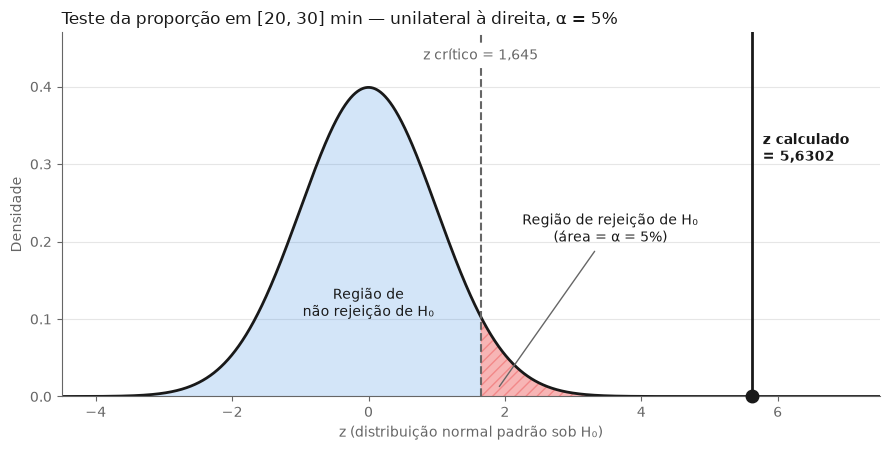

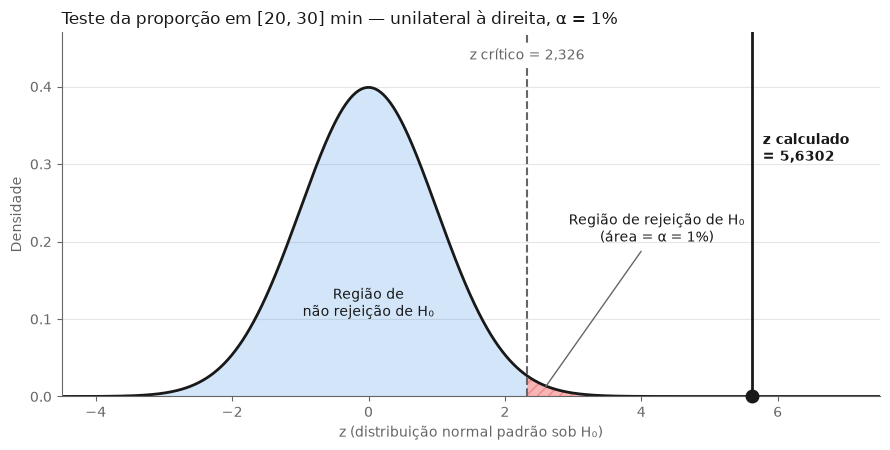

In [6]:
for alpha in (0.05, 0.01):
    grafico_regioes(
        z_calc=z_calc, z_crit=stats.norm.ppf(1 - alpha), cauda="direita", alpha=alpha,
        titulo=f"Teste da proporção em [20, 30] min — unilateral à direita, α = {int(alpha*100)}%",
        arquivo=f"teste_proporcao_alfa_{int(alpha*100):02d}.png", xlim=(-4.5, 7.5))

### Decisão e conclusão

- **α = 5%:** z crítico = 1,645. Região de rejeição: z ≥ 1,645. Como z_calc = 5,6302 está na região de rejeição, **rejeita-se H₀**. Ao nível de 5%, há evidência estatística de que a proporção de carregamentos entre 20 e 30 min após a padronização é maior que 30,97%.
- **α = 1%:** z crítico = 2,326. Região de rejeição: z ≥ 2,326. Como z_calc = 5,6302 também está na região de rejeição, **rejeita-se H₀**. Mesmo ao nível de 1%, há evidência de aumento da proporção na faixa-alvo.

Em termos de proporção: p̂ precisaria ser de pelo menos 38,57% (5%) ou 41,72% (1%) para rejeitar H₀. O valor observado, 57%, supera os dois limites.

## 5. Questão 3c — comparação com a análise preliminar

A conclusão **coincide** com a análise preliminar da Questão 1: a proporção na faixa-alvo aumentou, e o aumento (de cerca de 31% para 57%) é estatisticamente significativo nos dois níveis.

Ressalvas: (i) o teste não estabelece causalidade, pois outros fatores do período posterior podem ter contribuído; (ii) p₀ depende do modelo normal ajustado à Planilha 1, embora a frequência observada (32,33%) leve à mesma decisão (seção 6); (iii) 43% dos carregamentos ainda ficaram fora da faixa-alvo, então a melhora é significativa, mas não elimina tempos acima de 30 minutos.

## 6. Análise de sensibilidade (complementar)

In [7]:
p0_obs = antes.between(A, B, inclusive="both").mean()
z_obs = (p_chapeu - p0_obs) / np.sqrt(p0_obs * (1 - p0_obs) / n)
print(f"Usando a frequência observada da Planilha 1 como p0 = {br(p0_obs)} → z = {br(z_obs)}")
print("Decisão igual: rejeitar H0 para α = 5% e α = 1%.")

Usando a frequência observada da Planilha 1 como p0 = 0,3233 → z = 5,2735
Decisão igual: rejeitar H0 para α = 5% e α = 1%.


## 7. Por que o intervalo [20, 43] da Questão 5 original não foi usado

In [8]:
p0_ant = stats.norm.cdf(43, mu, sigma) - stats.norm.cdf(20, mu, sigma)
ph_ant = depois.between(20, 43, inclusive="both").mean()
print(f"[20, 43]: p0 = {br(p0_ant)} | p̂ = {br(ph_ant, 2)} | n·(1 − p0) = {br(n*(1-p0_ant), 3)}")

[20, 43]: p0 = 0,9973 | p̂ = 0,98 | n·(1 − p0) = 0,273


Com [20, 43], praticamente todos os carregamentos caem no intervalo (p₀ ≈ 99,73%). O valor n·(1 − p₀) ≈ 0,27 viola a condição da aproximação normal, e o intervalo não mede o objetivo da intervenção (reduzir o tempo para até 30 min). Por isso a análise usa [20, 30], o mesmo intervalo da Questão 7.4.